In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def design_matrix(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1: X = X.reshape(-1, 1)
    return np.column_stack((np.ones(len(X)), X))

def standardise(X_train, X_other):
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0, ddof=0)
    sigma = np.where(sigma == 0, 1., sigma)
    return (X_train-mu)/sigma, (X_other-mu)/sigma, mu, sigma

def sigmoid(z):
   
    return 1.0 / (1.0 + np.exp(-z))

def fit_logistic(X, y, lr=0.1, max_iter=30000, tol=1e-10):

    X, y = np.asarray(X, float), np.asarray(y, float)
    w = np.zeros(X.shape[1]); history=[]
    for i in range(max_iter):
        p = sigmoid(X @ w)
        grad = X.T @ (p-y)/len(y)
        new_w = w - lr*grad
        if i % 100 == 0:
            loss = np.mean(np.logaddexp(0, X @ new_w)-y*(X @ new_w))
            history.append(loss)
        if np.max(np.abs(new_w-w)) < tol:
            w=new_w; break
        w=new_w
    return w, np.asarray(history)
def confusion_matrix_scratch_2(y_true, y_pred):
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fp, tn, fn
def confusion_matrix_scratch(y_true, y_pred):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred)
    tn=int(np.sum((y_true==0)&(y_pred==0)))
    fp=int(np.sum((y_true==0)&(y_pred==1)))
    fn=int(np.sum((y_true==1)&(y_pred==0)))
    tp=int(np.sum((y_true==1)&(y_pred==1)))
    return np.array([[tn,fp],[fn,tp]])

def classification_metrics(y_true, y_pred):
    tn,fp,fn,tp=confusion_matrix_scratch(y_true,y_pred).ravel()
    safe=lambda a,b: a/b if b else 0.
    precision=safe(tp,tp+fp); recall=safe(tp,tp+fn)
    return dict(accuracy=safe(tp+tn,tp+tn+fp+fn), precision=precision,
                recall=recall, f1=safe(2*precision*recall,precision+recall))

def roc_curve_scratch(y_true, p):

    thresholds = np.sort(np.unique(p))[::-1]
    thresholds = np.concatenate(([1.1], thresholds, [-0.1]))
    
    fpr_list, tpr_list = [], []
    for th in thresholds:
        y_pred = (p >= th).astype(int)
        tp, fp, tn, fn = confusion_matrix_scratch_2(y_true, y_pred)
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        tpr_list.append(tpr)
        fpr_list.append(fpr)
        
    fpr_arr = np.array(fpr_list)
    tpr_arr = np.array(tpr_list)
    sort_idx = np.argsort(fpr_arr)
    return fpr_arr[sort_idx], tpr_arr[sort_idx]

def auc_trapezoid(fpr,tpr):
    fpr=np.asarray(fpr,float);tpr=np.asarray(tpr,float)
    
    return float(np.sum(np.diff(fpr)*(tpr[1:]+tpr[:-1])/2))

path=Path('ic272_lab8_loans.csv')

df=pd.read_csv(path)
required={'income_k','utilisation','employment','defaulted'}

X=df[['income_k','utilisation']].to_numpy(float)
emp=df['employment'].to_numpy()
y=df['defaulted'].to_numpy(int)
set(np.unique(y))=={0,1}
idx=np.random.default_rng(0).permutation(len(y))
te,tr=idx[:100],idx[100:]
X_train,y_train,emp_train=X[tr],y[tr],emp[tr]
X_test,y_test,emp_test=X[te],y[te],emp[te]
print('Train/test:',len(tr),len(te)); print('Employment categories:',pd.unique(emp))

Train/test: 400 100
Employment categories: ['salaried' 'student' 'self_employed' 'retired']


In [2]:
p=np.full(400,0.01)
print(np.prod(p))
print(np.sum(np.log(p)))

0.0
-1842.0680743952366


In [9]:
df.head()


,income_k,utilisation,employment,defaulted
0,40.5,0.723,salaried,0
1,146.6,0.613,student,0
2,66.1,0.578,salaried,0
3,126.7,0.420,self_employed,0
4,74.9,0.355,salaried,0


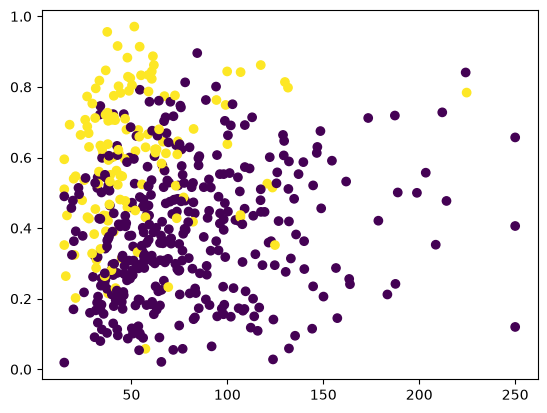

In [14]:
mask=[df['defaulted']==1]
plt.scatter(df['income_k'],df['utilisation'],c=mask)


(array([101., 155., 109.,  56.,  41.,  17.,   7.,   5.,   6.,   3.]),
 array([ 15. ,  38.5,  62. ,  85.5, 109. , 132.5, 156. , 179.5, 203. ,
        226.5, 250. ]),
 <BarContainer object of 10 artists>)

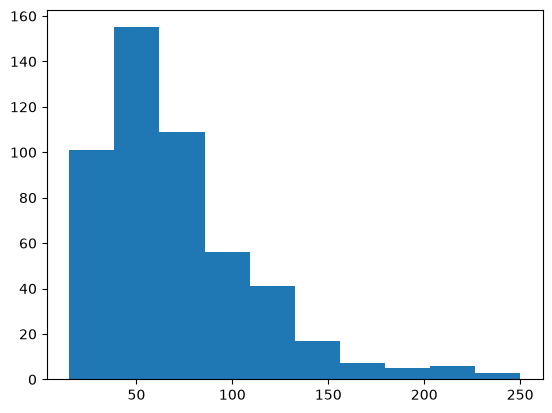

In [30]:
plt.hist(df['income_k'])

(array([23., 51., 68., 73., 82., 70., 61., 40., 25.,  7.]),
 array([0.019 , 0.1142, 0.2094, 0.3046, 0.3998, 0.495 , 0.5902, 0.6854,
        0.7806, 0.8758, 0.971 ]),
 <BarContainer object of 10 artists>)

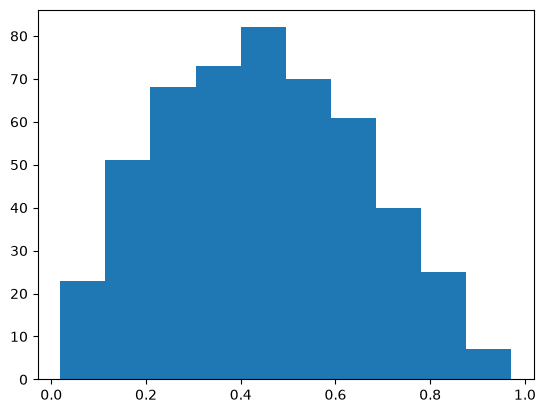

In [29]:
plt.hist(df['utilisation'])

In [21]:
def gaussian_pdf(x, mu, var):
    var=np.maximum(np.asarray(var,float),1e-12)
    return np.exp(-0.5*(np.asarray(x)-mu)**2/var)/np.sqrt(2*np.pi*var)

def fit_gaussian_nb(X,y):
    X=np.asarray(X,float); y=np.asarray(y,int)
    classes=np.array([0,1])
    counts=np.array([np.sum(y==c) for c in classes])
    
    priors=counts/len(y)
    means=np.vstack([X[y==c].mean(axis=0) for c in classes])
    variances=np.vstack([X[y==c].var(axis=0,ddof=0) for c in classes])
    return priors,means,np.maximum(variances,1e-12)

example_X=np.array([160,170,165,150,155,145],float).reshape(-1,1)
example_y=np.array([0,0,0,1,1,1])
ep,em,ev=fit_gaussian_nb(example_X,example_y)
pa=float(gaussian_pdf(162,em[0,0],ev[0,0])); pb=float(gaussian_pdf(162,em[1,0],ev[1,0]))
posterior_a=pa*ep[0]/(pa*ep[0]+pb*ep[1])
print(' P(162|A), P(162|B), P(A|162):',pa,pb,posterior_a)

priors,means,variances=fit_gaussian_nb(X_train,y_train)
print('Class priors [0,1]:',priors)
print('Means :\n',means)
print('Variances \n',variances)


 P(162|A), P(162|B), P(A|162): 0.07459782769363346 0.001299671301370867 0.9828759666842724
Class priors [0,1]: [0.7425 0.2575]
Means :
 [[77.66329966  0.38854209]
 [53.77864078  0.58560194]]
Variances 
 [[1.81430003e+03 3.21900462e-02]
 [1.03564498e+03 3.57098901e-02]]


In [5]:
def nb_log_scores(X,priors,means,variances):
    X=np.asarray(X,float)
    if X.ndim==1: X=X.reshape(1,-1)
    v=np.maximum(variances,1e-12)
    return np.log(priors)[None,:]-0.5*np.sum(
        np.log(2*np.pi*v)[None,:,:]+(X[:,None,:]-means[None,:,:])**2/v[None,:,:],axis=2)

def predict_proba_nb(X,priors,means,variances):
    L=nb_log_scores(X,priors,means,variances)
    return sigmoid(L[:,1]-L[:,0])

nb_prob=predict_proba_nb(X_test,priors,means,variances)
nb_pred=(nb_prob>=0.5).astype(int)
print('Confusion matrix [[TN,FP],[FN,TP]]:\n',confusion_matrix_scratch(y_test,nb_pred))
print(pd.Series(classification_metrics(y_test,nb_pred)).to_string())


Confusion matrix [[TN,FP],[FN,TP]]:
 [[63  7]
 [11 19]]
accuracy     0.820000
precision    0.730769
recall       0.633333
f1           0.678571


Logistic weights (intercept, income_k, utilisation): [-1.59396339 -1.13311055  1.3476339 ]
Gaussian NB AUC: 0.88762 Logistic AUC: 0.89571
Higher test AUC: Logistic regression


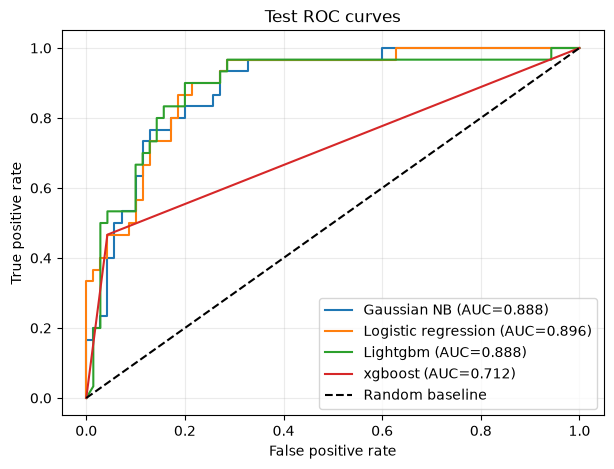

In [41]:
Xtr_s,Xte_s,train_mu,train_sd=standardise(X_train,X_test)
w,loss_history=fit_logistic(design_matrix(Xtr_s),y_train)
log_prob=sigmoid(design_matrix(Xte_s)@w)
nb_fpr,nb_tpr=roc_curve_scratch(y_test,nb_prob)
lr_fpr,lr_tpr=roc_curve_scratch(y_test,log_prob)
lgb_fpr,lgb_tpr=roc_curve_scratch(y_test,y_pred_prob)
xgb_fpr,xgb_tpr=roc_curve_scratch(y_test,y_pred_xg)
nb_auc=auc_trapezoid(nb_fpr,nb_tpr)
lr_auc=auc_trapezoid(lr_fpr,lr_tpr)
lgb_auc=auc_trapezoid(lgb_fpr,lgb_tpr)
xgb_auc=auc_trapezoid(xgb_fpr,xgb_tpr)
print('Logistic weights (intercept, income_k, utilisation):',w)
print('Gaussian NB AUC:',round(nb_auc,5),'Logistic AUC:',round(lr_auc,5))
print('Higher test AUC:', 'Gaussian NB' if nb_auc>lr_auc else 'Logistic regression' if lr_auc>nb_auc else 'Tie')
plt.figure(figsize=(7,5))
plt.plot(nb_fpr,nb_tpr,label=f'Gaussian NB (AUC={nb_auc:.3f})')
plt.plot(lr_fpr,lr_tpr,label=f'Logistic regression (AUC={lr_auc:.3f})')
plt.plot(lgb_fpr,lgb_tpr,label=f'Lightgbm (AUC={lgb_auc:.3f})')
plt.plot(xgb_fpr,xgb_tpr,label=f'xgboost (AUC={xgb_auc:.3f})')
plt.plot([0,1],[0,1],'k--',label='Random baseline')
plt.xlabel('False positive rate');plt.ylabel('True positive rate')
plt.title('Test ROC curves');plt.legend();plt.grid(alpha=.25);plt.show()

In [42]:
import lightgbm as lgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
params={
"objective":"binary",
"metric":["auc","binary_logloss"],
"boosting_type":"gbdt",
"learning_rate":0.05,
"num_leaves":31,
"max_depth":-1,
"feature_fraction":0.8,
"bagging_fraction":0.8,
"bagging_freq":5,
"lambda_l1":0.1,
"lambda_l2":0.2,
"min_data_in_leaf":20,
"verbose":-1
}
train_data=lgb.Dataset(X_train,label=y_train)
valid_data=lgb.Dataset(X_test,label=y_test,reference=train_data)
model=lgb.train(
params,
train_data,
num_boost_round=1000,
valid_sets=[train_data,valid_data],
valid_names=["train","valid"],
callbacks=[lgb.early_stopping(50)]
)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[69]	train's auc: 0.926122	train's binary_logloss: 0.309682	valid's auc: 0.887857	valid's binary_logloss: 0.383943


In [39]:
y_pred_prob=model.predict(X_test,num_iteration=model.best_iteration)

In [35]:
print(y_pred_prob)

[0.70632185 0.81375835 0.5436857  0.81375835 0.193935   0.02800855
 0.04749936 0.55925916 0.01703447 0.01746824 0.89354934 0.11484376
 0.01591521 0.16836191 0.9091038  0.91530152 0.0353025  0.08413986
 0.49019709 0.79077815 0.07666806 0.15861944 0.05800685 0.43460431
 0.08438557 0.0550371  0.09280387 0.01836874 0.15088409 0.69693845
 0.10271511 0.03694572 0.04744121 0.06536941 0.03830234 0.21860381
 0.49220197 0.82056938 0.27595925 0.04184048 0.08256864 0.1941528
 0.54196697 0.01968294 0.04162184 0.03640941 0.21710607 0.01591521
 0.72371304 0.0353025  0.63232771 0.03043041 0.03543787 0.05220972
 0.17210334 0.02002261 0.31178861 0.67120554 0.78793289 0.02360523
 0.20381739 0.12063666 0.7464238  0.02244484 0.41357962 0.03043041
 0.2024928  0.14808282 0.07044961 0.10271511 0.04506018 0.12520598
 0.02180275 0.1046069  0.24927909 0.02358068 0.91458456 0.06094025
 0.06366839 0.02882477 0.26842861 0.46567478 0.15260604 0.02129718
 0.85289997 0.58057151 0.91530152 0.6016234  0.23655692 0.28905

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
params_xg = {
    'objective':'binary:logistic',
    'max_depth':4,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

model_xgb = XGBClassifier(**params_xg)

model_xgb.fit(X_train, y_train)

y_pred_xg = model_xgb.predict(X_test)
print(y_pred_xg)

[1 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0]
